# Análise do Relatório Mundial de Felicidade (2019)

**Etapa 2 - Desafio SYNAPTA** | UNINASSAU Maceió (Edital nº 1/2026)  
**Aluno:** Leonardo Dantas Andrade de Alencar - 01701668  
**Opção escolhida:** Opção 2, Análise do Relatório Mundial de Felicidade  
**Ferramentas:** Python 3, Google Colab, pandas e matplotlib

## Objetivo e pergunta orientadora

Analisar indicadores de felicidade de 156 países e responder:

> Quais fatores aparecem associados às maiores pontuações de felicidade e quais cuidados devem ser tomados ao interpretar essa relação?

**Fonte:** [World Happiness Report (Kaggle, Sustainable Development Solutions Network)](https://www.kaggle.com/datasets/unsdsn/world-happiness)  
**Arquivo utilizado:** 2019.csv  
**Licença:** CC0 1.0 Universal (domínio público), conforme a página do dataset. Por isso o arquivo está incluído em data/.

## Colunas utilizadas

O dataset é centrado na coluna `Score`. As outras colunas de fatores estimam o quanto cada um contribui para o `Score` de cada país.

| Coluna | O que representa |
|---|---|
| `Country or region` | Nome do país. Cada linha é um país ou região. |
| `Score` | Média das notas que as pessoas dão à própria vida, numa escala de 0 a 10. |
| `Social support` | Estimativa de quanto o suporte social contribui para o `Score` do país. Não é o valor bruto do indicador. |
| `Freedom to make life choices` | Estimativa de quanto a liberdade para fazer escolhas de vida contribui para o `Score` do país. Não é o valor bruto do indicador. |

As colunas de fatores medem a contribuição em relação à "Distopia", um país hipotético com as piores médias do mundo em cada fator, por isso o mínimo delas é 0. Um valor 0 significa que o fator contribuiu zero para o `Score` daquele país, e não que o fator não existe nele.

## Carregamento e verificação dos dados

As células a seguir carregam o `2019.csv` e verificam tamanho, valores ausentes, duplicados e inconsistências.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('2019.csv')

In [5]:
# Estatísticas gerais de cada coluna (média, desvio, mínimo, máximo, quartis)
df.describe()

,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000
mean,78.500000,5.407096,0.905147,1.208814,0.725244,0.392571,0.184846,0.110603
std,45.177428,1.113120,0.398389,0.299191,0.242124,0.143289,0.095254,0.094538
min,1.000000,2.853000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,39.750000,4.544500,0.602750,1.055750,0.547750,0.308000,0.108750,0.047000
50%,78.500000,5.379500,0.960000,1.271500,0.789000,0.417000,0.177500,0.085500
75%,117.250000,6.184500,1.232500,1.452500,0.881750,0.507250,0.248250,0.141250
max,156.000000,7.769000,1.684000,1.624000,1.141000,0.631000,0.566000,0.453000


In [ ]:
# (linhas, colunas): esperado 156 países e 9 colunas
df.shape

(156, 9)

In [6]:
# Tabela de True/False: True = valor ausente (a contagem resumida está na célula seguinte)
df.isnull()

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
151,False,False,False,False,False,False,False,False,False
152,False,False,False,False,False,False,False,False,False
153,False,False,False,False,False,False,False,False,False
154,False,False,False,False,False,False,False,False,False


In [7]:
# Total de valores ausentes por coluna
df.isnull().sum()

,0
Overall rank,0
Country or region,0
Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,0


In [ ]:
# Linhas repetidas
df.duplicated().sum()

np.int64(0)

In [ ]:
# Países repetidos (o Overall rank muda em toda linha, então a checagem anterior não pegaria isso)
df.duplicated(subset=["Country or region"]).sum()

np.int64(0)

In [ ]:
# Países com valor 0 em cada coluna de fator
for c in df.columns[3:9]:
    print(c, df.loc[df[c] == 0, "Country or region"].tolist())

GDP per capita ['Somalia']
Social support ['Central African Republic']
Healthy life expectancy ['Swaziland']
Freedom to make life choices ['Afghanistan']
Generosity ['Greece']
Perceptions of corruption ['Moldova']


### Resumo da limpeza e preparação

- **Tamanho:** 156 linhas (países) e 9 colunas.
- **Valores ausentes:** nenhum.
- **Duplicados:** Nenhum, tanto na linha inteira quanto só pela coluna de país. A segunda checagem foi necessária porque o `Overall rank` é diferente em toda linha, então a primeira não encontraria um país repetido com dados diferentes.
- **Inconsistências:** Nenhum valor negativo; o `Score` fica entre 2,853 e 7,769, faixa coerente para uma nota de 0 a 10.
- **Valores zero:** Cada coluna de fator tem um país com valor 0 (Somália no PIB, República Centro-Africana no suporte social, Suazilândia na expectativa de vida, Afeganistão na liberdade, Grécia na generosidade e Moldávia na percepção de corrupção). Como cada coluna é uma contribuição em relação à Distopia, 0 significa contribuição zero e não que há dados faltando, então foram mantidos.
- **Decisão:** Nenhuma alteração foi necessária nos dados.

## Média e mediana do Score

A média do `Score` é aproximadamente **5,407** e a mediana é **5,3795**. A média representa a nota média se todos os 156 países fossem tratados igualmente. A mediana é o valor central: metade dos países está abaixo dela e metade acima. Os dois valores são muito próximos, o que indica uma distribuição equilibrada, sem países extremos puxando a média.

In [ ]:
# Média do Score
df["Score"].mean()

np.float64(5.407096153846155)

In [ ]:
# Mediana do Score (valor central)
df["Score"].median()

5.3795

In [ ]:
# 10 países com maior Score
df.nlargest(10, "Score")

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298
5,6,Switzerland,7.480,1.452,1.526,1.052,0.572,0.263,0.343
6,7,Sweden,7.343,1.387,1.487,1.009,0.574,0.267,0.373
7,8,New Zealand,7.307,1.303,1.557,1.026,0.585,0.330,0.380
8,9,Canada,7.278,1.365,1.505,1.039,0.584,0.285,0.308
9,10,Austria,7.246,1.376,1.475,1.016,0.532,0.244,0.226


In [ ]:
# 10 países com menor Score
df.nsmallest(10, "Score")

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
155,156,South Sudan,2.853,0.306,0.575,0.295,0.010,0.202,0.091
154,155,Central African Republic,3.083,0.026,0.000,0.105,0.225,0.235,0.035
153,154,Afghanistan,3.203,0.350,0.517,0.361,0.000,0.158,0.025
152,153,Tanzania,3.231,0.476,0.885,0.499,0.417,0.276,0.147
151,152,Rwanda,3.334,0.359,0.711,0.614,0.555,0.217,0.411
150,151,Yemen,3.380,0.287,1.163,0.463,0.143,0.108,0.077
149,150,Malawi,3.410,0.191,0.560,0.495,0.443,0.218,0.089
148,149,Syria,3.462,0.619,0.378,0.440,0.013,0.331,0.141
147,148,Botswana,3.488,1.041,1.145,0.538,0.455,0.025,0.100
146,147,Haiti,3.597,0.323,0.688,0.449,0.026,0.419,0.110


### Top 10 e bottom 10

| # | Maiores pontuações | Score | | Menores pontuações | Score |
|---|---|---|---|---|---|
| 1 | Finlândia | 7,769 | | Sudão do Sul | 2,853 |
| 2 | Dinamarca | 7,600 | | República Centro-Africana | 3,083 |
| 3 | Noruega | 7,554 | | Afeganistão | 3,203 |
| 4 | Islândia | 7,494 | | Tanzânia | 3,231 |
| 5 | Países Baixos | 7,488 | | Ruanda | 3,334 |
| 6 | Suíça | 7,480 | | Iêmen | 3,380 |
| 7 | Suécia | 7,343 | | Malawi | 3,410 |
| 8 | Nova Zelândia | 7,307 | | Síria | 3,462 |
| 9 | Canadá | 7,278 | | Botsuana | 3,488 |
| 10 | Áustria | 7,246 | | Haiti | 3,597 |

## Correlação do Score com dois fatores

Foi usada a correlação de Pearson, que mede o quanto duas variáveis variam juntas de forma linear (de -1 a 1).

| Fator | Correlação com o Score |
|---|---|
| Suporte social | 0,777 |
| Liberdade para fazer escolhas | 0,567 |

Ambas são positivas, e o suporte social apresentou a associação mais forte entre os dois fatores analisados. Isso contraria minha hipótese inicial de que a liberdade acompanharia mais de perto o `Score`.

In [ ]:
# Correlação de Pearson entre Score e liberdade
df["Score"].corr(df["Freedom to make life choices"])

np.float64(0.5667418257199898)

In [ ]:
# Correlação de Pearson entre Score e suporte social
df["Score"].corr(df["Social support"])

np.float64(0.7770577880638644)

**Gráfico 1: Suporte social x Score**

Cada ponto é um país. A nuvem sobe da esquerda para a direita: países em que o suporte social contribui mais para o Score tendem a ter Score maior. Os países com Score alto ficam concentrados na faixa alta de suporte social, enquanto os de Score baixo variam bastante. O ponto isolado em zero, à esquerda, é a República Centro-Africana, que tem suporte social 0.

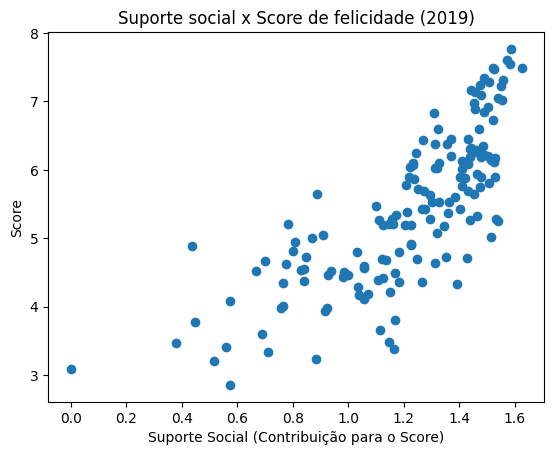

In [ ]:
plt.scatter(df["Social support"], df["Score"])
plt.title("Suporte social x Score de felicidade (2019)")
plt.xlabel("Suporte Social (Contribuição para o Score)")
plt.ylabel("Score")
plt.savefig("grafico1.png")
plt.show()

**Gráfico 2: Top 10 países por Score**

Gráfico de barras horizontais com os 10 países de maior Score, da Finlândia à Áustria. As barras têm tamanhos muito parecidos, o que indica que o topo do ranking é bem apertado: a diferença entre o 1º e o 10º é de cerca de 0,5 ponto. O eixo começa em 0, o que também ajuda a deixar as barras parecidas.

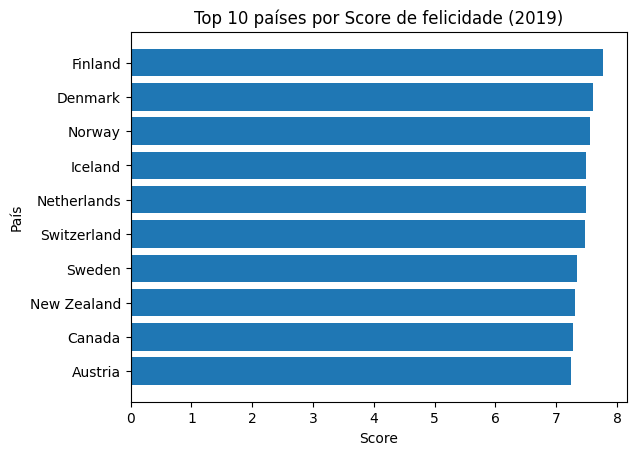

In [ ]:
top10 = df.nlargest(10, "Score")
plt.barh(top10['Country or region'], top10['Score'])
plt.title("Top 10 países por Score de felicidade (2019)")
plt.xlabel("Score")
plt.ylabel("País")
plt.gca().invert_yaxis()
plt.savefig("grafico2.png", bbox_inches="tight")
plt.show()

**Gráfico 3: Liberdade para fazer escolhas x Score**

Cada ponto é um país. A tendência também é de subida, mas a nuvem é mais espalhada que a do suporte social, o que combina com a correlação mais fraca (0,567). Para uma mesma contribuição da liberdade, os Scores variam bastante, então esse fator sozinho acompanha menos o Score.

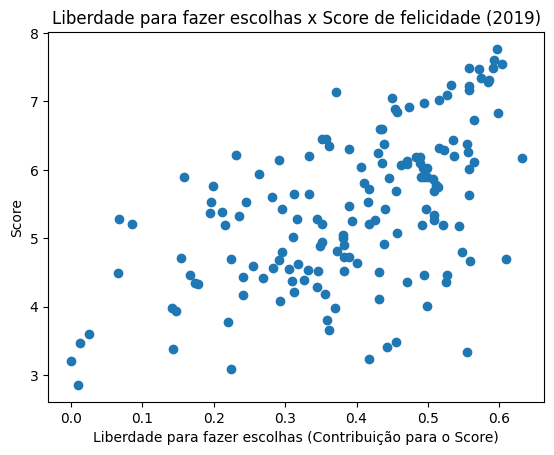

In [ ]:
plt.scatter(df["Freedom to make life choices"], df["Score"])
plt.title("Liberdade para fazer escolhas x Score de felicidade (2019)")
plt.xlabel("Liberdade para fazer escolhas (Contribuição para o Score)")
plt.ylabel("Score")
plt.savefig("grafico3.png")
plt.show()

## Análise extra: por que a soma dos fatores não dá o Score?

Somando as seis colunas de fatores da Finlândia, o resultado é 5,055, e não 7,769. A diferença (2,714) vem do componente da Distopia e de um resíduo, que é a parte que o modelo não explica. A célula abaixo calcula essa diferença para cada país (`sobra`).

In [8]:
fatores = df.columns[3:9]
df["soma_fatores"] = df[fatores].sum(axis=1)   # soma dos 6 fatores, linha por linha
df["sobra"] = df["Score"] - df['soma_fatores'] # parte do Score que os fatores não explicam
print(fatores)
df[["Country or region", "Score", "soma_fatores", "sobra"]].head(1)  # Finlândia: 5,055 e 2,714

Index(['GDP per capita', 'Social support', 'Healthy life expectancy',
       'Freedom to make life choices', 'Generosity',
       'Perceptions of corruption'],
      dtype='object')


,Country or region,Score,soma_fatores,sobra
0,Finland,7.769,5.055,2.714


## Tentativas e dificuldades

- Minha hipótese inicial era que a liberdade para fazer escolhas teria a associação mais forte com o Score, mas os dados mostraram o contrário (0,567 contra 0,777 do suporte social).
- Ao somar os fatores, rodei a célula mais de uma vez e a soma da Finlândia saiu 10,110 (o dobro de 5,055), porque `df.columns[3:]` passou a incluir a própria coluna `soma_fatores`. Corrigi limitando a fatia com `df.columns[3:9]`.

## Conclusões

1. **O topo é dominado por países europeus, principalmente nórdicos.** Os 10 maiores Scores vão de 7,246 (Áustria) a 7,769 (Finlândia), com Dinamarca, Noruega, Islândia, Países Baixos, Suíça e Suécia entre eles. Canadá e Nova Zelândia são as únicas exceções entre os países europeus do top 10.
2. **A base do ranking é bem mais baixa e mais espalhada.** Os 10 menores vão de 2,853 (Sudão do Sul) a 3,597 (Haiti), uma faixa de cerca de 0,7 contra cerca de 0,5 do topo.
3. **Entre os dois fatores analisados, o suporte social tem a associação mais forte com o Score.** A correlação foi de 0,777, e no gráfico os pontos sobem da esquerda para a direita.
4. **A liberdade de escolhas tem associação moderada.** A correlação foi de 0,567 e a nuvem de pontos é mais espalhada. Isso contrariou minha hipótese inicial.
5. **Há exceções à tendência.** Botsuana e Iêmen têm suporte social intermediário, abaixo da mediana de 1,27 (1,145 e 1,163, respectivamente), e Score baixo (3,488 e 3,380). Eles são exceções porque o Score deles é muito menor do que a contribuição do suporte social sugere.

## Correlação não é causa

A correlação ou associação indica que dois valores têm tendência a variar juntos, mas não prova que um cause o outro. O suporte social (correlação de 0,777) pode acompanhar um Score alto sem ser a única causa da felicidade. Pode haver outros fatores influenciando os dois ao mesmo tempo, e a relação pode até ser no sentido contrário, pois pessoas felizes podem relatar mais suporte social.

## Limitações

- **Diferenças culturais:** O Score vem de uma nota que as pessoas dão à própria vida, e culturas diferentes podem avaliar e responder de formas diferentes, o que dificulta a comparação entre países.
- **Método de pesquisa:** O Score vem de amostras da pesquisa Gallup World Poll, e não de toda a população. As colunas dos fatores são estimativas de um modelo estatístico, e não medidas diretas, então a correlação com o Score já nasce parcialmente embutida.
- **Retrato de um período:** O arquivo é referente a 2019. Não mostra mudanças ao longo do tempo, e eventos posteriores podem ter alterado o cenário. A descrição do dataset no Kaggle é de uma edição anterior do relatório (cita amostras de 2013 a 2016 e uma coluna "Family"), então não foi usada para afirmar o período exato dos dados de 2019.
- **Análise simples:** Foi usada correlação entre duas variáveis sem controlar outros fatores.
- **Seleção de fatores:** Só foram analisados dois fatores (suporte social e liberdade). PIB per capita, expectativa de vida saudável, generosidade e percepção de corrupção ficaram de fora.
- **Possível extensão:** Analisar por continente ou região enriqueceria os dados, mas o arquivo de 2019 não traz essa informação.

## Declaração de uso de inteligência artificial generativa

- **Ferramenta:** Claude (Anthropic).
- **Finalidade:** Usei como tutor durante o desafio para orientar o raciocínio, explicar conceitos (média, mediana, percentis, correlação), ajudar a interpretar mensagens de erro, sugerir rascunhos de textos e revisar o projeto.
- **O que fiz sozinho:** Escrevi e executei todo o código no Google Colab, depurei os erros que apareceram, escolhi os dois fatores analisados e fiz a hipótese inicial. Solicitei ajuda para melhor compreender os conceitos e reescrevi os textos do README e do notebook com minha própria redação, conferindo cada número no meu notebook.
- **Como verifiquei:** Todos os números (dimensões, ausentes, duplicados, valores zero, média, mediana, top 10, bottom 10 e correlações) vieram da execução do meu notebook. O dataset e os gráficos foram conferidos visualmente. A escala de 0 a 10, a origem dos dados (Gallup World Poll) e o significado das colunas de fatores foram conferidos na descrição do dataset no Kaggle.
